In [1]:

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from pathlib import Path

# Load the cleaned dataset
data_path = Path(
    r"C:\Users\ANKIT TRIPATHI\Supply-Chain-Inventory-Analysis"
    r"\data\Supply_Chain_Cleaned.csv"
)

df_eda = pd.read_csv(data_path)

df_eda["Order_Date"] = pd.to_datetime(df_eda["Order_Date"])
df_eda["Delivery_Date"] = pd.to_datetime(df_eda["Delivery_Date"])

print("Dataset loaded successfully!")
print("Shape:", df_eda.shape)
display(df_eda.head())


Dataset loaded successfully!
Shape: (15000, 14)


,Product_ID,Product_Name,Category,Supplier_Name,Order_Date,Delivery_Date,Stock_Quantity,Reorder_Level,Units_Sold,Purchase_Cost,Selling_Price,Warehouse_Location,Shipping_Time_Days,Profit_Per_Unit
0,PROD1000,Tablet,Fashion,Supplier D,2023-08-02,2023-08-07,3,59,241,1800,2081,Chennai,5,281
1,PROD1001,Tablet,Fashion,Supplier D,2024-04-11,2024-04-13,118,105,70,1950,2169,Hyderabad,2,219
2,PROD1002,Mixer,Sports,Supplier A,2024-08-16,2024-08-20,57,108,107,828,1322,Bangalore,4,494
3,PROD1003,TV,Sports,Supplier B,2024-11-30,2024-12-02,420,129,271,317,598,Chennai,2,281
4,PROD1004,Mixer,Fashion,Supplier C,2024-08-03,2024-08-11,401,77,210,645,1061,Mumbai,8,416


In [2]:

# Product-wise business analysis

product_analysis = (
    df_eda.groupby("Product_Name")
    .agg(
        Total_Units_Sold=("Units_Sold", "sum"),
        Total_Stock=("Stock_Quantity", "sum"),
        Average_Profit_Per_Unit=("Profit_Per_Unit", "mean"),
        Total_Gross_Profit=(
            "Profit_Per_Unit",
            lambda x: (x * df_eda.loc[x.index, "Units_Sold"]).sum()
        )
    )
    .reset_index()
)

product_analysis = product_analysis.sort_values(
    by="Total_Units_Sold",
    ascending=False
)

display(product_analysis.round(2))


,Product_Name,Total_Units_Sold,Total_Stock,Average_Profit_Per_Unit,Total_Gross_Profit
1,Camera,240401,385172,277.92,67289924
3,Laptop,227840,388520,273.97,62301164
4,Mixer,226878,392830,268.11,61423945
8,Tablet,222857,375131,276.29,60869550
5,Phone,220936,375709,275.68,59786820
2,Fan,220851,381003,277.08,61626332
9,Watch,219547,376463,279.34,61540660
0,AC,218074,367080,273.14,60185648
7,TV,217051,366446,276.48,60042822
6,Shoes,208073,355415,280.36,57857339


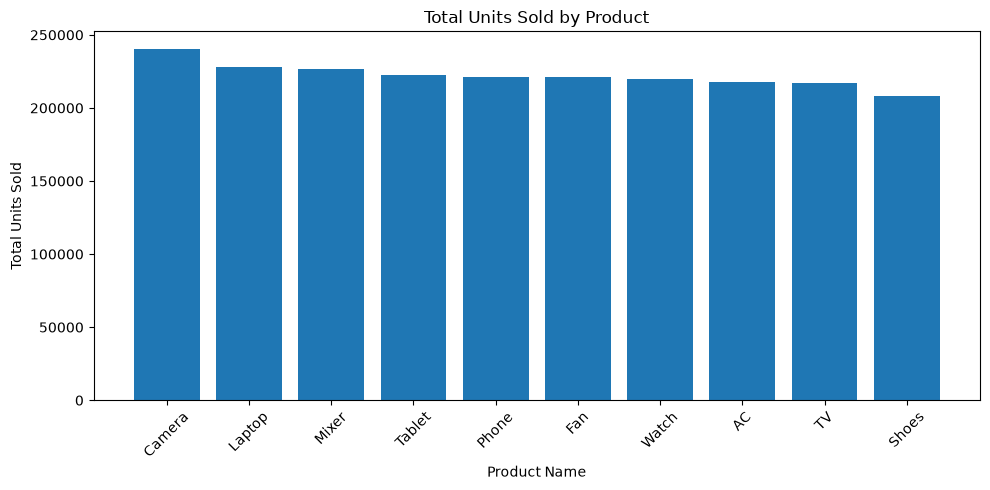

In [3]:

# Chart 1: Total Units Sold by Product

product_sales_chart = product_analysis.sort_values(
    by="Total_Units_Sold",
    ascending=False
)

plt.figure(figsize=(10, 5))

plt.bar(
    product_sales_chart["Product_Name"],
    product_sales_chart["Total_Units_Sold"]
)

plt.title("Total Units Sold by Product")
plt.xlabel("Product Name")
plt.ylabel("Total Units Sold")
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()


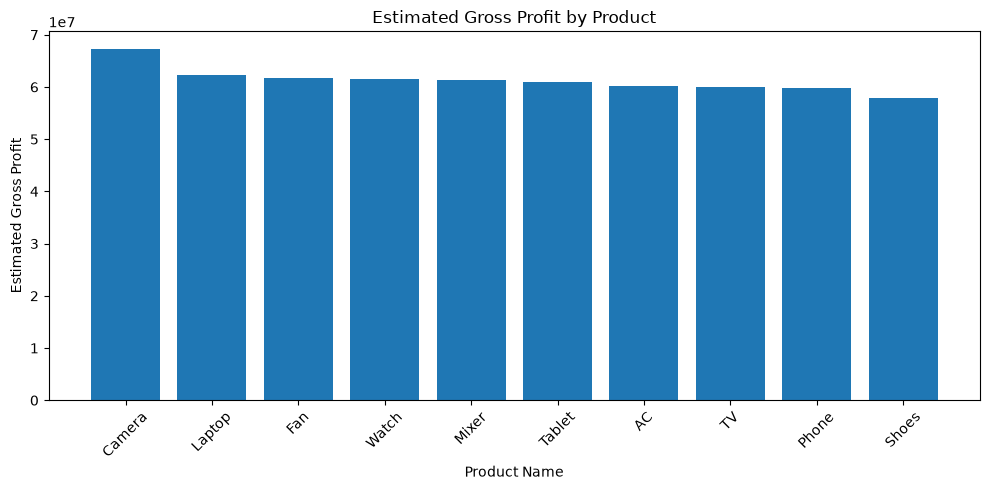

In [4]:

# Chart 2: Estimated Gross Profit by Product

product_profit_chart = product_analysis.sort_values(
    by="Total_Gross_Profit",
    ascending=False
)

plt.figure(figsize=(10, 5))

plt.bar(
    product_profit_chart["Product_Name"],
    product_profit_chart["Total_Gross_Profit"]
)

plt.title("Estimated Gross Profit by Product")
plt.xlabel("Product Name")
plt.ylabel("Estimated Gross Profit")
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()


In [5]:

# Supplier-wise business analysis

supplier_analysis = (
    df_eda.groupby("Supplier_Name")
    .agg(
        Total_Units_Sold=("Units_Sold", "sum"),
        Total_Stock=("Stock_Quantity", "sum"),
        Average_Shipping_Days=("Shipping_Time_Days", "mean"),
        Average_Profit_Per_Unit=("Profit_Per_Unit", "mean"),
        Total_Gross_Profit=(
            "Profit_Per_Unit",
            lambda x: (
                x * df_eda.loc[x.index, "Units_Sold"]
            ).sum()
        )
    )
    .reset_index()
)

display(
    supplier_analysis.sort_values(
        by="Total_Gross_Profit",
        ascending=False
    ).round(2)
)


,Supplier_Name,Total_Units_Sold,Total_Stock,Average_Shipping_Days,Average_Profit_Per_Unit,Total_Gross_Profit
4,Supplier E,452768,750660,5.55,277.17,125550272
2,Supplier C,448597,762095,5.39,274.67,124050671
0,Supplier A,447389,761035,5.48,277.67,123069384
1,Supplier B,442191,749617,5.52,275.28,122865551
3,Supplier D,431563,740362,5.54,274.17,117388326


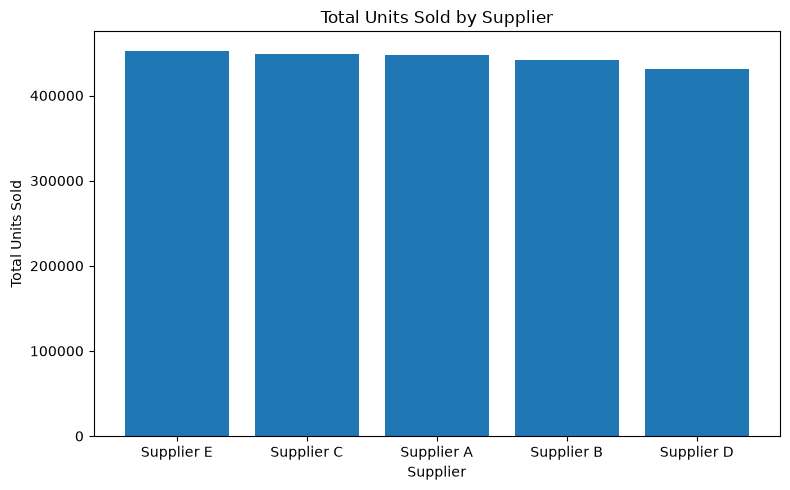

In [6]:

supplier_sales_chart = supplier_analysis.sort_values(
    by="Total_Units_Sold",
    ascending=False
)

plt.figure(figsize=(8, 5))
plt.bar(
    supplier_sales_chart["Supplier_Name"],
    supplier_sales_chart["Total_Units_Sold"]
)
plt.title("Total Units Sold by Supplier")
plt.xlabel("Supplier")
plt.ylabel("Total Units Sold")
plt.tight_layout()
plt.show()


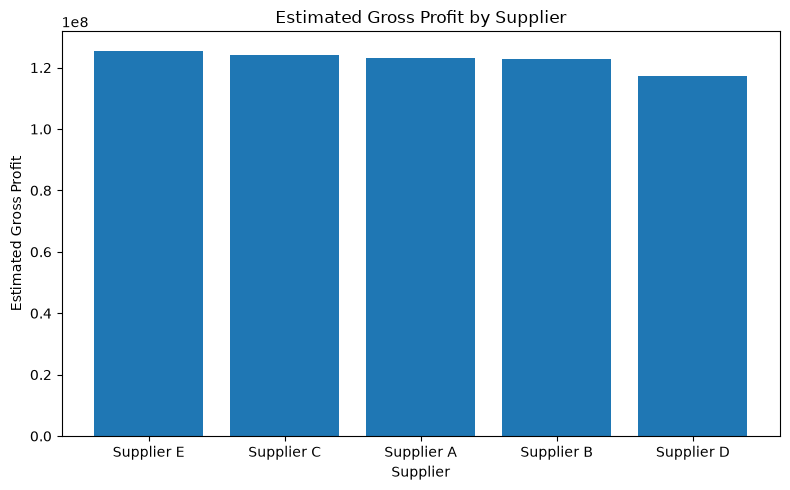

In [7]:

supplier_profit_chart = supplier_analysis.sort_values(
    by="Total_Gross_Profit",
    ascending=False
)

plt.figure(figsize=(8, 5))
plt.bar(
    supplier_profit_chart["Supplier_Name"],
    supplier_profit_chart["Total_Gross_Profit"]
)
plt.title("Estimated Gross Profit by Supplier")
plt.xlabel("Supplier")
plt.ylabel("Estimated Gross Profit")
plt.tight_layout()
plt.show()


In [8]:

# Warehouse-wise business analysis

df_eda["At_or_Below_Reorder"] = (
    df_eda["Stock_Quantity"] <= df_eda["Reorder_Level"]
)

warehouse_analysis = (
    df_eda.groupby("Warehouse_Location")
    .agg(
        Total_Stock=("Stock_Quantity", "sum"),
        Total_Units_Sold=("Units_Sold", "sum"),
        Total_Records=("Product_ID", "count"),
        Average_Shipping_Days=("Shipping_Time_Days", "mean"),
        Low_Stock_Records=("At_or_Below_Reorder", "sum")
    )
    .reset_index()
)

display(
    warehouse_analysis.sort_values(
        by="Total_Stock",
        ascending=False
    ).round(2)
)


,Warehouse_Location,Total_Stock,Total_Units_Sold,Total_Records,Average_Shipping_Days,Low_Stock_Records
0,Bangalore,761135,449298,3002,5.55,567
4,Mumbai,757200,451363,3024,5.53,615
3,Hyderabad,755963,447781,3032,5.44,607
1,Chennai,753070,438034,3010,5.53,629
2,Delhi,736401,436032,2932,5.43,597


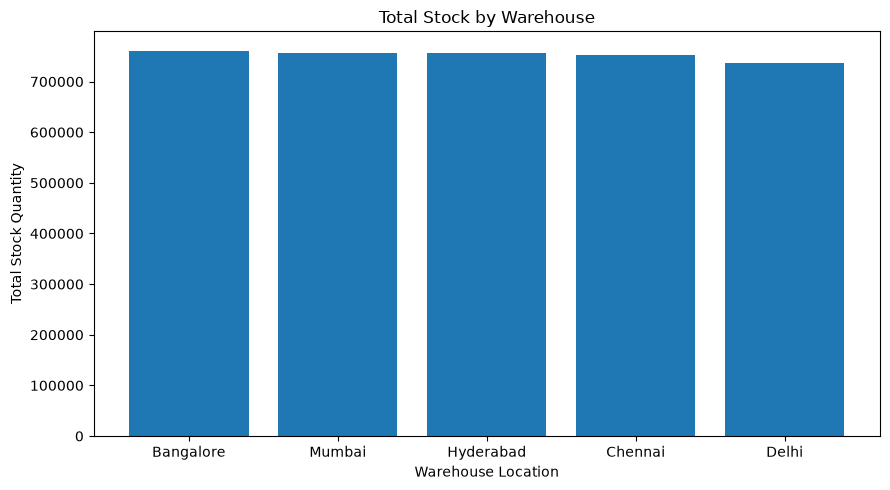

In [9]:

warehouse_stock_chart = warehouse_analysis.sort_values(
    by="Total_Stock",
    ascending=False
)

plt.figure(figsize=(9, 5))
plt.bar(
    warehouse_stock_chart["Warehouse_Location"],
    warehouse_stock_chart["Total_Stock"]
)
plt.title("Total Stock by Warehouse")
plt.xlabel("Warehouse Location")
plt.ylabel("Total Stock Quantity")
plt.tight_layout()
plt.show()


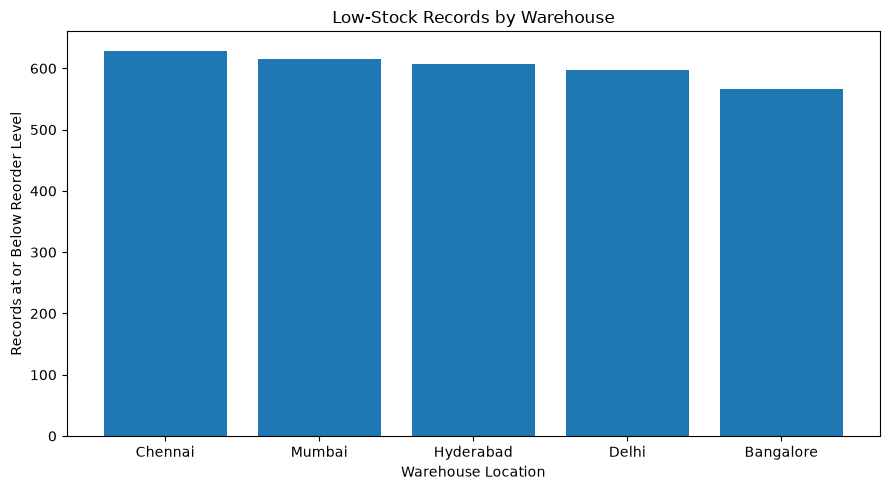

In [10]:

warehouse_low_stock_chart = warehouse_analysis.sort_values(
    by="Low_Stock_Records",
    ascending=False
)

plt.figure(figsize=(9, 5))
plt.bar(
    warehouse_low_stock_chart["Warehouse_Location"],
    warehouse_low_stock_chart["Low_Stock_Records"]
)
plt.title("Low-Stock Records by Warehouse")
plt.xlabel("Warehouse Location")
plt.ylabel("Records at or Below Reorder Level")
plt.tight_layout()
plt.show()


In [11]:

# Shipping performance summary

shipping_summary = df_eda["Shipping_Time_Days"].agg(
    ["mean", "median", "min", "max"]
)

print("Shipping Performance Summary")
print("----------------------------")
print(f"Average shipping days: {shipping_summary['mean']:.2f}")
print(f"Median shipping days: {shipping_summary['median']:.2f}")
print(f"Minimum shipping days: {shipping_summary['min']}")
print(f"Maximum shipping days: {shipping_summary['max']}")


Shipping Performance Summary
----------------------------
Average shipping days: 5.50
Median shipping days: 6.00
Minimum shipping days: 1.0
Maximum shipping days: 10.0


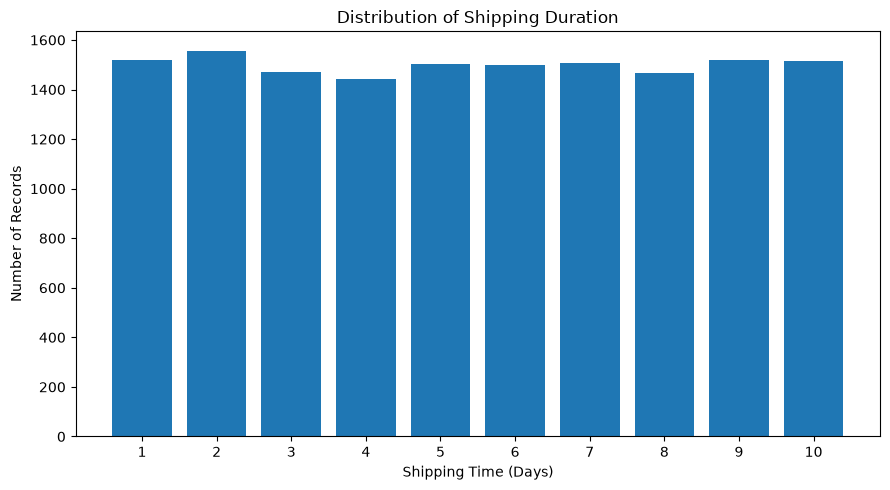

In [12]:

shipping_counts = (
    df_eda["Shipping_Time_Days"]
    .value_counts()
    .sort_index()
)

plt.figure(figsize=(9, 5))
plt.bar(
    shipping_counts.index,
    shipping_counts.values
)
plt.title("Distribution of Shipping Duration")
plt.xlabel("Shipping Time (Days)")
plt.ylabel("Number of Records")
plt.xticks(range(1, 11))
plt.tight_layout()
plt.show()


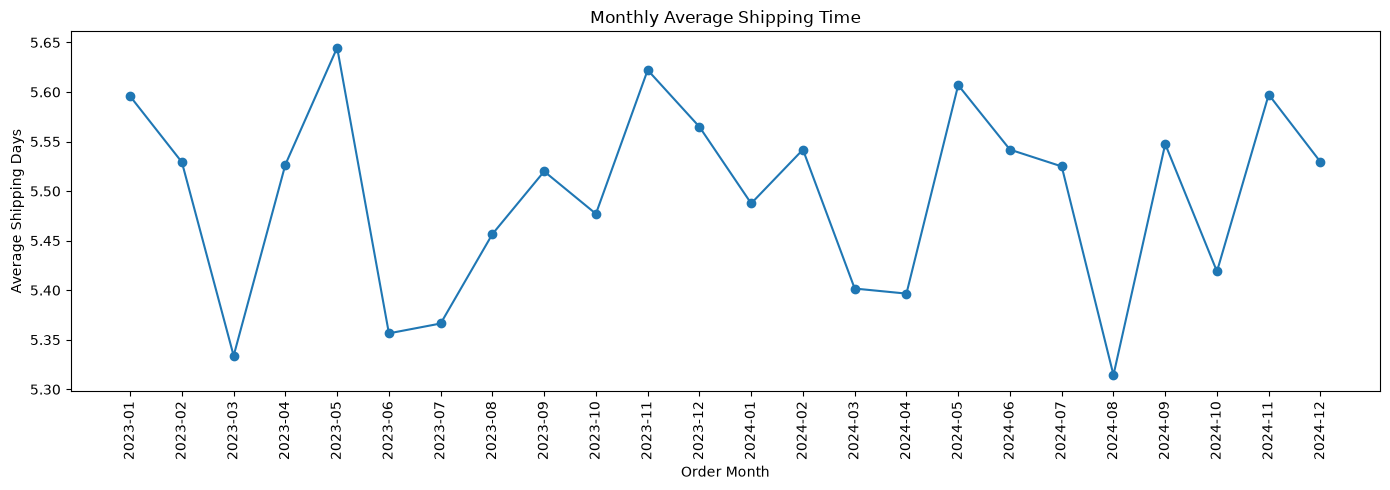

,Order_Month,Average_Shipping_Days,Total_Records
0,2023-01,5.60,653
1,2023-02,5.53,599
2,2023-03,5.33,647
3,2023-04,5.53,653
4,2023-05,5.64,653
5,2023-06,5.36,648
6,2023-07,5.37,655
7,2023-08,5.46,600
8,2023-09,5.52,602
9,2023-10,5.48,633


In [13]:

# Create month-wise summary

df_eda["Order_Month"] = (
    df_eda["Order_Date"]
    .dt.to_period("M")
    .astype(str)
)

monthly_shipping = (
    df_eda.groupby("Order_Month")
    .agg(
        Average_Shipping_Days=("Shipping_Time_Days", "mean"),
        Total_Records=("Product_ID", "count")
    )
    .reset_index()
)

plt.figure(figsize=(14, 5))
plt.plot(
    monthly_shipping["Order_Month"],
    monthly_shipping["Average_Shipping_Days"],
    marker="o"
)
plt.title("Monthly Average Shipping Time")
plt.xlabel("Order Month")
plt.ylabel("Average Shipping Days")
plt.xticks(rotation=90)
plt.tight_layout()
plt.show()

display(monthly_shipping.round(2))


In [14]:

# Final Business Findings

top_selling_product = product_analysis.loc[
    product_analysis["Total_Units_Sold"].idxmax()
]

top_profit_product = product_analysis.loc[
    product_analysis["Total_Gross_Profit"].idxmax()
]

highest_stock_warehouse = warehouse_analysis.loc[
    warehouse_analysis["Total_Stock"].idxmax()
]

most_low_stock_warehouse = warehouse_analysis.loc[
    warehouse_analysis["Low_Stock_Records"].idxmax()
]

top_profit_supplier = supplier_analysis.loc[
    supplier_analysis["Total_Gross_Profit"].idxmax()
]

total_low_stock_records = int(
    df_eda["At_or_Below_Reorder"].sum()
)

average_shipping = df_eda["Shipping_Time_Days"].mean()

print("========== FINAL BUSINESS FINDINGS ==========")

print(
    f"Top-selling product: {top_selling_product['Product_Name']} "
    f"({top_selling_product['Total_Units_Sold']:,.0f} units)"
)

print(
    f"Highest estimated gross-profit product: "
    f"{top_profit_product['Product_Name']} "
    f"({top_profit_product['Total_Gross_Profit']:,.2f})"
)

print(
    f"Warehouse with highest recorded stock: "
    f"{highest_stock_warehouse['Warehouse_Location']} "
    f"({highest_stock_warehouse['Total_Stock']:,.0f} units)"
)

print(
    f"Warehouse with most low-stock records: "
    f"{most_low_stock_warehouse['Warehouse_Location']} "
    f"({most_low_stock_warehouse['Low_Stock_Records']:,.0f} records)"
)

print(
    f"Supplier with highest estimated gross profit: "
    f"{top_profit_supplier['Supplier_Name']} "
    f"({top_profit_supplier['Total_Gross_Profit']:,.2f})"
)

print(f"Average shipping duration: {average_shipping:.2f} days")
print(f"Total records at or below reorder level: {total_low_stock_records:,}")


========== FINAL BUSINESS FINDINGS ==========
Top-selling product: Camera (240,401 units)
Highest estimated gross-profit product: Camera (67,289,924.00)
Warehouse with highest recorded stock: Bangalore (761,135 units)
Warehouse with most low-stock records: Chennai (629 records)
Supplier with highest estimated gross profit: Supplier E (125,550,272.00)
Average shipping duration: 5.50 days
Total records at or below reorder level: 3,015


## Business Insights and Recommendations

1. **Product performance:** Identify high-selling products and ensure sufficient stock is available to meet demand.
2. **Profitability:** Review products with high estimated gross profit to understand which products contribute most to sales-based gross profit.
3. **Inventory management:** Investigate records where stock is at or below the reorder level and prioritize replenishment where necessary.
4. **Warehouse planning:** Compare warehouse stock levels with sales and low-stock records to identify potential inventory imbalances.
5. **Supplier performance:** Compare suppliers using estimated gross profit and associated shipping duration before making procurement decisions.
6. **Shipping performance:** Monitor monthly average shipping duration and investigate unusual increases if they occur.

**Metric limitation:** Estimated gross profit is calculated as `(Selling Price − Purchase Cost) × Units Sold`. It does not include operating, storage, transportation, or other expenses, and should not be described as net profit.